# Phát hiện xe bằng mạng toàn tích chập (PyTorch)

Bản PyTorch của `Yêu cầu/examples/5. Others/2_obj_detection.ipynb` (gốc dựa trên `HTuennermann/Vehicle-Detection-and-Tracking`), giữ nguyên thứ tự mục và cấu hình của gốc.

- Dữ liệu: ảnh màu 64×64, nhãn +1 (xe) / −1 (không phải xe).
- Mô hình **toàn tích chập** (không có lớp Dense): chuẩn hóa `x/127.5 − 1` → Conv 10 → Conv 10 → MaxPool 8×8 → Dropout 0.25 → Conv 128 kernel 8×8 ("dense1") → Dropout 0.5 → Conv 1 kernel 1×1 tanh ("dense2"). Với ảnh 64×64 đầu ra là 1×1, tức một điểm số.
- Huấn luyện: loss MSE, Adam mặc định (lr 1e-3), batch 128, 5 epoch.
- Phần (4): cho **cả ảnh lớn** `test.jpg` qua cùng mạng để được bản đồ điểm số (heatmap), vẽ khung quanh vùng có điểm > 0.99.

| | Keras gốc (Keras 2.0.9) | PyTorch |
|---|---|---|
| Số tham số | 83.367 | kiểm bằng `assert` ở mục (2) |
| Test "accuracy" (cách Keras tính, xem mục (3)) | 0.9523 | xem mục (3) |
| Test loss (MSE) | 0.0642 | xem mục (3) |

# Import libraries

Keras gốc:
```python
import glob
from skimage.io import imread
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pylab as plt
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Flatten, Lambda
from keras.layers import Conv2D, MaxPooling2D
```

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # để import pytorch/common.py
from common import *

import glob
import torch.nn.functional as F
from skimage.io import imread
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# True: chỉ chạy thử (ít ảnh, 1 epoch); bản nộp là False (chạy được cả trên CPU)
CHAY_THU = False

set_seed(0)
device = get_device()
TEN = "2_obj_detection"

torch 2.15.0+cpu | thiết bị: cpu


# (1) Data

Keras gốc:
```python
cars = glob.glob("./data/obj_detection/vehicles/*/*.png")
non_cars = glob.glob("./data/obj_detection/non-vehicles/*/*.png")
Y = np.concatenate([np.ones(len(cars)), np.zeros(len(non_cars)) - 1])
X = []
for name in cars:
    X.append(imread(name))
for name in non_cars:
    X.append(imread(name))
X = np.array(X)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30)
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
```

Khác Keras:
- Đọc từ `Yêu cầu/examples/5. Others/car_data/...` (có sẵn trong repo). `sorted(glob...)` để thứ tự file giống nhau trên mọi máy.
- Gốc chia train/test **không đặt seed**, nên mỗi lần chạy một cách chia khác; ở đây đặt `random_state=0` để chạy lại ra cùng kết quả. Cùng tỷ lệ 70/30, cùng số ảnh (12.432 / 5.328).
- Không chuẩn hóa ở bước này: như gốc, việc chuẩn hóa nằm trong mô hình (`Lambda`).
- `(N, 64, 64, 3)` → `(N, 3, 64, 64)`; nhãn ±1 để shape `(N, 1)` cho khớp đầu ra.

In [2]:
GOC = EXAMPLES_DIR / "5. Others" / "car_data" / "data" / "obj_detection"
cars = sorted(glob.glob(str(GOC / "vehicles" / "*" / "*.png")))
non_cars = sorted(glob.glob(str(GOC / "non-vehicles" / "*" / "*.png")))
if CHAY_THU:
    cars, non_cars = cars[::20], non_cars[::20]
print(len(cars), "ảnh xe,", len(non_cars), "ảnh không phải xe")

Y = np.concatenate([np.ones(len(cars)), np.zeros(len(non_cars)) - 1])
X = []
for name in cars:
    X.append(imread(name))
for name in non_cars:
    X.append(imread(name))
X = np.array(X)

8792 ảnh xe, 8968 ảnh không phải xe


In [3]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=0)

X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
print('X_train shape:', X_train.shape)
print(X_train.shape[0], 'train samples')
print(X_test.shape[0], 'test samples')

x_train, x_test = to_nchw(X_train), to_nchw(X_test)                     # (N, 3, 64, 64), 0–255
y_train = torch.tensor(Y_train, dtype=torch.float32).unsqueeze(1)      # (N, 1), ±1
y_test = torch.tensor(Y_test, dtype=torch.float32).unsqueeze(1)

X_train shape: (12432, 64, 64, 3)
12432 train samples
5328 test samples


# (2) Declare model

Keras gốc:
```python
def get_conv(input_shape=(64, 64, 3), filename=None):
    model = Sequential()
    model.add(Lambda(lambda x: x/127.5 - 1., input_shape=input_shape, output_shape=input_shape))
    model.add(Conv2D(10, (3, 3), activation='relu', name='conv1', input_shape=input_shape, padding="same"))
    model.add(Conv2D(10, (3, 3), activation='relu', name='conv2', padding="same"))
    model.add(MaxPooling2D(pool_size=(8, 8)))
    model.add(Dropout(0.25))
    model.add(Conv2D(128, (8, 8), activation="relu", name="dense1"))
    model.add(Dropout(0.5))
    model.add(Conv2D(1, (1,1), name="dense2", activation="tanh"))
    if filename:
        model.load_weights(filename)
    return model

model = get_conv()
model.add(Flatten())
```

Khác Keras:
- `Lambda(lambda x: x/127.5 - 1.)` thành một dòng đầu `forward`: đưa 0–255 về −1…1.
- Conv của PyTorch không gắn với kích thước ảnh vào, nên **một** mô hình dùng được cả cho ảnh 64×64 (train) và ảnh lớn (heatmap). Gốc phải dựng mô hình thứ hai `get_conv(input_shape=(None, None, 3))` rồi nạp lại trọng số từ file `localize.h5`.
- `Flatten` cuối chỉ áp khi train (đầu ra `(N, 1, 1, 1)` → `(N, 1)`), thông qua tham số `flatten=True`; khi vẽ heatmap thì giữ bản đồ `(1, 1, h, w)`.
- Đầu ra giữ `tanh` (bài hồi quy về ±1 với MSE, không phải phân loại bằng softmax).

In [4]:
class CarConv(nn.Module):
    """get_conv(): mạng toàn tích chập, tên lớp như Keras (conv1, conv2, dense1, dense2)."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 10, 3, padding=1)        # 3·9·10 + 10 = 280
        self.conv2 = nn.Conv2d(10, 10, 3, padding=1)       # 910
        self.pool = nn.MaxPool2d(8)
        self.dropout1 = nn.Dropout(0.25)
        self.dense1 = nn.Conv2d(10, 128, 8)                # 10·64·128 + 128 = 82.048, 'valid'
        self.dropout2 = nn.Dropout(0.5)
        self.dense2 = nn.Conv2d(128, 1, 1)                 # 129

    def forward(self, x, flatten=True):                    # x: (N, 3, H, W), giá trị 0–255
        x = x / 127.5 - 1.0                                # Lambda
        x = F.relu(self.conv1(x))                          # (N, 10, H, W)
        x = F.relu(self.conv2(x))
        x = self.dropout1(self.pool(x))                    # (N, 10, H/8, W/8)
        x = self.dropout2(F.relu(self.dense1(x)))          # (N, 128, H/8 − 7, W/8 − 7)
        x = torch.tanh(self.dense2(x))                     # (N, 1, H/8 − 7, W/8 − 7); 64×64 → 1×1
        return x.flatten(1) if flatten else x


model = init_keras_like(CarConv()).to(device)
summary(model, input_size=(1, 3, 64, 64))
n_params = count_params(model)
print("Số tham số PyTorch:", n_params)
assert n_params == 83_367

Số tham số PyTorch: 83367


# (3) Train defined model

Keras gốc:
```python
model.compile(loss='mse', optimizer='adam', metrics=['accuracy'])
model.fit(X_train, Y_train, batch_size=128, epochs=5, verbose=1, validation_data=(X_test, Y_test))
score = model.evaluate(X_test, Y_test, verbose=0)
print('Test score:', score[0])
print('Test accuracy:', score[1])
model.save_weights("localize.h5")
```

**"accuracy" của gốc là gì?** Loss là MSE và đầu ra có 1 giá trị, nên Keras 2.0.9 hiểu `'accuracy'` là `binary_accuracy`: so `round(dự đoán)` với nhãn. Nhãn là ±1 và `tanh` cho giá trị trong (−1, 1), nên một mẫu chỉ được tính đúng khi dự đoán > 0,5 (xe) hoặc < −0,5 (không xe); dự đoán trong (−0,5; 0,5) làm tròn thành 0 và luôn bị tính sai. Đây không phải accuracy phân loại thông thường. Notebook tính cả hai:
- `keras_accuracy`: đúng cách của Keras, dùng để so với 0.9523.
- `sign_accuracy` (trong `common.py`): đúng khi cùng dấu với nhãn, là accuracy phân loại thật khi lấy ngưỡng 0.

In [5]:
def keras_accuracy(output, target):
    """binary_accuracy của Keras: round(dự đoán) == nhãn."""
    return (torch.round(output) == target).float().mean()


loss_fn = nn.MSELoss()                                   # 'mse'
optimizer = torch.optim.Adam(model.parameters())         # 'adam': lr 1e-3, mặc định như Keras
batch_size = 128
epochs = 1 if CHAY_THU else 5

train_loader = make_loader(x_train, y_train, batch_size=batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size=batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs, metric=keras_accuracy)
train_time = time.time() - starting_time
print('> training time is %.4f minutes' % (train_time / 60))

score = evaluate(model, test_loader, loss_fn, keras_accuracy)
_, score_sign = evaluate(model, test_loader, loss_fn, sign_accuracy)
print('Test score:', score[0])
print('Test accuracy:', score[1], '(cách Keras: round(dự đoán) == nhãn)')
print('Test accuracy theo dấu:', score_sign)

if not CHAY_THU:
    torch.save(model.state_dict(), results_dir(TEN) / "localize.pt")   # = save_weights("localize.h5"); git bỏ qua .pt

Epoch 1/5 - 23.6s - loss: 0.4704 - acc: 0.5380 - val_loss: 0.1854 - val_acc: 0.8438


Epoch 2/5 - 20.1s - loss: 0.1801 - acc: 0.8641 - val_loss: 0.1160 - val_acc: 0.9133


Epoch 3/5 - 16.8s - loss: 0.1152 - acc: 0.9176 - val_loss: 0.0679 - val_acc: 0.9486


Epoch 4/5 - 22.3s - loss: 0.0833 - acc: 0.9406 - val_loss: 0.0629 - val_acc: 0.9570


Epoch 5/5 - 22.7s - loss: 0.0680 - acc: 0.9541 - val_loss: 0.1074 - val_acc: 0.9375
> training time is 1.7576 minutes


Test score: 0.1074304467251709
Test accuracy: 0.9374999996420141 (cách Keras: round(dự đoán) == nhãn)
Test accuracy theo dấu: 0.9635885887675815


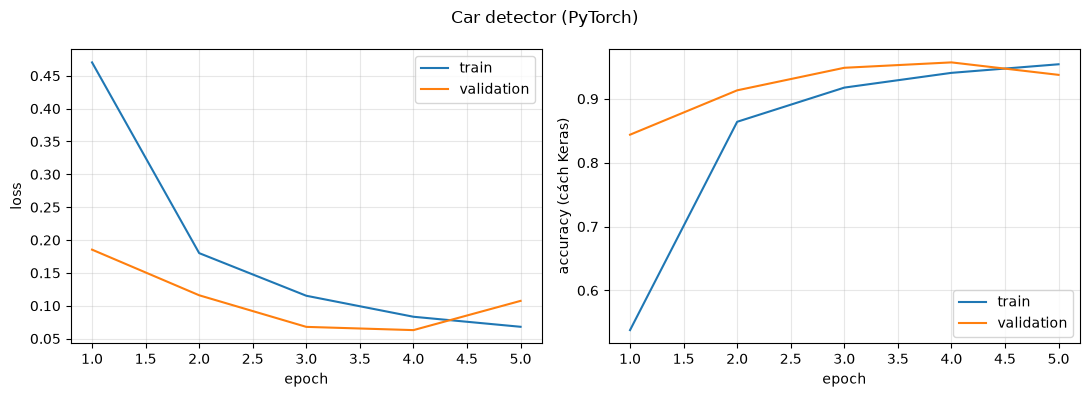

In [6]:
fig = plot_history(history, None if CHAY_THU else TEN, metric_label="accuracy (cách Keras)",
                   title="Car detector (PyTorch)")
plt.show()

In [7]:
if not CHAY_THU:
    save_history(history, TEN)
    save_metrics(TEN, test_loss=score[0], test_metric=score[1], test_sign_accuracy=score_sign,
                 n_params=n_params, epochs_ran=len(history["loss"]), best_epoch=None,
                 train_time_s=train_time, device=device_name(device), seed=0, split_random_state=0)
    ghi_so_sanh(TEN, "5. Others", "test_acc", keras=0.9523, pytorch=score[1],
                keras_params=83367, pytorch_params=n_params, epochs_keras=5, epochs_pytorch=epochs,
                optimizer="Adam", lr=0.001, batch=batch_size, device=device_name(device),
                train_time_s=train_time, seed=0,
                ghi_chu="accuracy tính như Keras (round == nhãn ±1); theo dấu = %.4f; "
                        "chia train/test random_state=0 (gốc không seed)" % score_sign)

so_sanh.csv: 2_obj_detection | test_acc Keras 0.9523 | PyTorch 0.9375 | chênh -0.0148


# (4) Evaluate trained model: heatmap trên ảnh lớn

Keras gốc:
```python
heatmodel = get_conv(input_shape=(None, None, 3), filename="localize.h5")

def locate():
    data = imread("test.jpg")
    heatmap = heatmodel.predict(data.reshape(1, data.shape[0], data.shape[1], data.shape[2]))
    sel_heatmap = heatmap[0, :, :, 0] > 0.99
    xx, yy = np.meshgrid(np.arange(heatmap.shape[2]), np.arange(heatmap.shape[1]))
    x = (xx[heatmap[0, :, :, 0] > 0.99])
    y = (yy[heatmap[0, :, :, 0] > 0.99])
    for i, j in zip(x, y):
        data[j*8:j*8+64, i*8] = (0, 255, 0)
        data[j*8:j*8+64, i*8+64] = (0, 255, 0)
        data[j*8, i*8:i*8+64] = (0, 255, 0)
        data[j*8+64, i*8:i*8+64] = (0, 255, 0)
    return heatmap[0, :, :, 0], sel_heatmap, data
```

Mỗi điểm (j, i) của heatmap ứng với một cửa sổ 64×64 bắt đầu ở pixel (8j, 8i) của ảnh (bước 8 do MaxPool 8×8), nên vẽ khung 64×64 tại đó. Ảnh `test.jpg` 720×1280 cho heatmap 83×153.

PyTorch dùng lại chính `model` (không cần dựng `heatmodel` và nạp file), gọi `forward(..., flatten=False)` ở chế độ `eval()`. Thêm một chỗ chặn chỉ số khi vẽ khung ở mép ảnh (gốc sẽ báo `IndexError` nếu có xe được phát hiện ở hàng/cột cuối của heatmap).

heatmap: (83, 153) | số ô > 0.99: 54


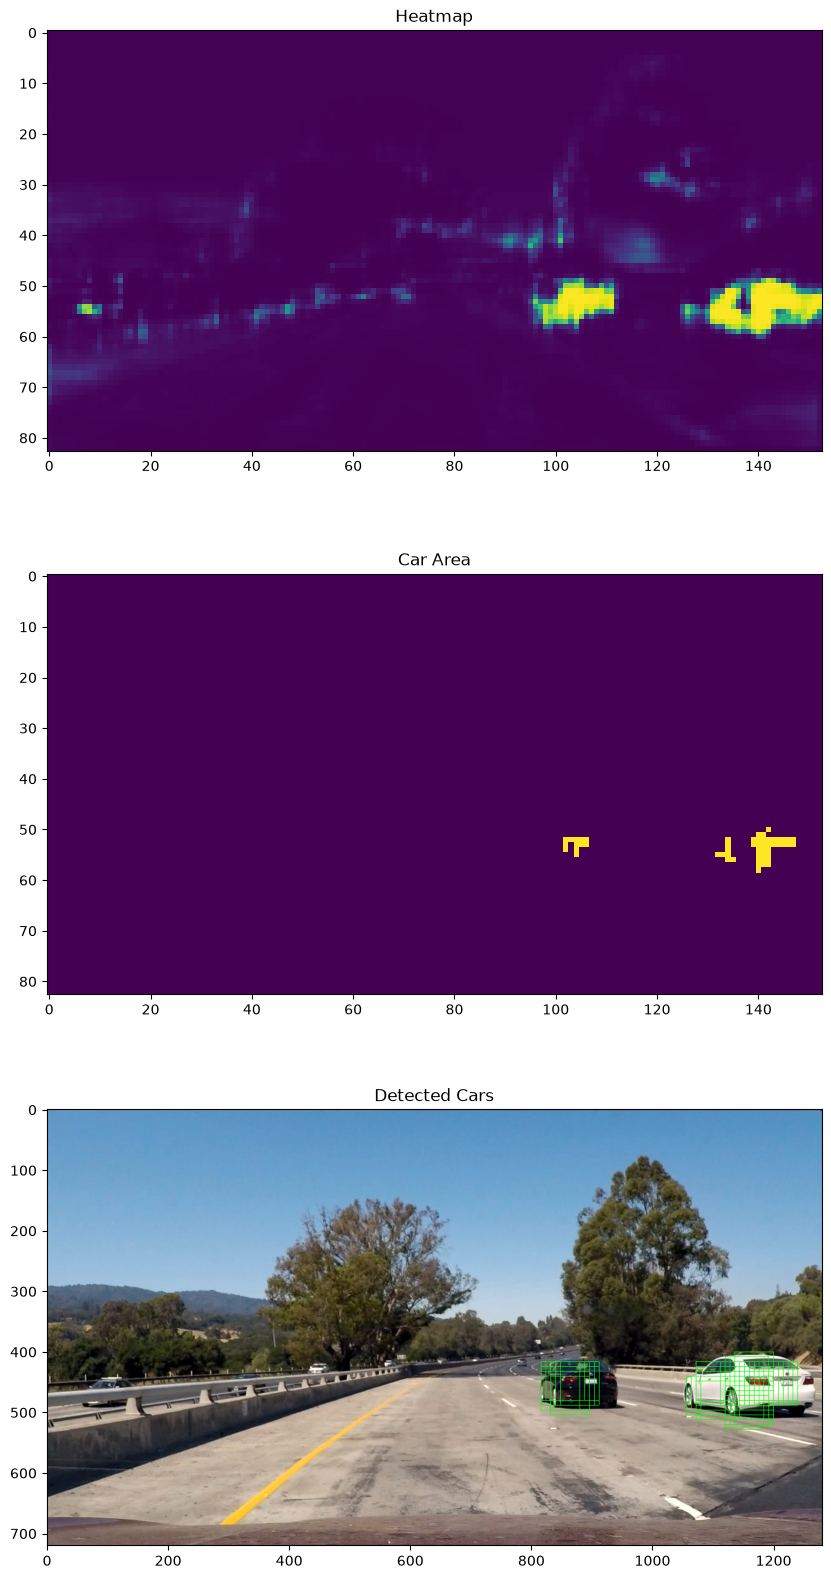

In [8]:
heatmodel = model      # cùng trọng số; conv PyTorch nhận ảnh kích thước bất kỳ


def locate():
    data = imread(str(EXAMPLES_DIR / "5. Others" / "test.jpg"))         # (720, 1280, 3) uint8
    x = to_nchw(data[np.newaxis]).to(device)                             # (1, 3, 720, 1280)
    heatmodel.eval()
    with torch.no_grad():
        heatmap = heatmodel(x, flatten=False).cpu().numpy()             # (1, 1, h, w)
    heatmap = heatmap.transpose(0, 2, 3, 1)                              # (1, h, w, 1) như Keras
    sel_heatmap = heatmap[0, :, :, 0] > 0.99

    xx, yy = np.meshgrid(np.arange(heatmap.shape[2]), np.arange(heatmap.shape[1]))
    x = (xx[heatmap[0, :, :, 0] > 0.99])
    y = (yy[heatmap[0, :, :, 0] > 0.99])

    H, W = data.shape[:2]
    for i, j in zip(x, y):
        # min(..., H-1/W-1): ô ở hàng/cột cuối có j*8+64 = H (hoặc i*8+64 = W), vượt ảnh 1 pixel;
        # gốc không gặp vì không có ô nào ở mép, ở đây chặn lại cho chắc
        bottom, right = min(j*8+64, H - 1), min(i*8+64, W - 1)
        data[j*8:j*8+64, i*8] = (0, 255, 0)
        data[j*8:j*8+64, right] = (0, 255, 0)

        data[j*8, i*8:i*8+64] = (0, 255, 0)
        data[bottom, i*8:i*8+64] = (0, 255, 0)
    return heatmap[0, :, :, 0], sel_heatmap, data


hm, sel_hm, annotated = locate()
print("heatmap:", hm.shape, "| số ô > 0.99:", int(sel_hm.sum()))

plt.figure(figsize=(10, 20))

plt.subplot(3, 1, 1)
plt.title("Heatmap")
plt.imshow(hm)

plt.subplot(3, 1, 2)
plt.title("Car Area")
plt.imshow(sel_hm)

plt.subplot(3, 1, 3)
plt.title("Detected Cars")
plt.imshow(annotated)
if not CHAY_THU:
    plt.savefig(results_dir(TEN) / "heatmap_test.png", dpi=100, bbox_inches="tight")
plt.show()